![Banner](../images/09_08_banner_rs_super_resolution.png)


# Image Super-Resolution

A 30 m Landsat pixel can hold a road, a field edge and two crops, and it stores one spectrum for all of them.

Five notebooks estimate a finer image that is consistent with that coarse observation, from the observation model to paired Landsat, Sentinel-2, PlanetScope, and 0.6 m imagery.

- **Image Super-Resolution.** This notebook. The observation model, classical and deep methods, the constraints of remote sensing, and a 10 m scene observed at 30 m.
- **Landsat 8 to Sentinel-2: six-band super-resolution.** Landsat 8 at 30 m (9 July 2019) to Sentinel-2 at 10 m (8 July), in blue, green, red, NIR, SWIR1, and SWIR2, with classical methods and a paired EDSR-style CNN.
- **Sentinel-2 to PlanetScope: multispectral super-resolution.** Sentinel-2 at 10 m as the input and PlanetScope at 3 m as the reference, in blue, green, red, and NIR.
- **PlanetScope to high-resolution NAIP-style imagery: super-resolution.** PlanetScope at 3 m (14 July 2019) to a 0.6 m reference in the same four bands.
- **Landsat 8, Sentinel-2, PlanetScope, and high-resolution imagery.** Two separate experiments over one rural window, Landsat to Sentinel-2 and PlanetScope to 0.6 m, not one chain.


## Overview

Super-resolution estimates a finer image that is consistent with that coarse observation. The estimate is useful for mapping, and it is under-determined: many different fine images degrade to the same coarse one. This notebook is the map of the subject. It sets out the observation model, the families of methods, the applications, and the shift since about 2021 toward transformers, realistic degradations and diffusion models. The next notebook runs the methods on Landsat 9 and Sentinel-2.

It assumes the optical introduction: ground sampling distance, mixed pixels, and the difference between Landsat and Sentinel-2. No deep-learning library is required here. The hands-on section uses a synthetic 10 m scene so that the true fine image is known.


## Core concepts

### Learning objectives

1. Write the blur-downsample-noise model and explain why super-resolution is ill-posed.
2. Separate interpolation, pan-sharpening, spatiotemporal fusion, multi-frame super-resolution and single-image super-resolution by the extra information each one uses.
3. Relate classical reconstruction, pansharpening and fusion methods to the deep-learning families that replaced their hand-designed priors.
4. Name the constraints that dominate remote sensing: spectral fidelity, bandpass differences, the real point-spread function, co-registration and land-cover change.
5. Match applications to methods, including the failure mode in each application.
6. Describe recent practice: attention, diffusion, blind degradation, learning without a fine twin, and evaluation that follows the decision the image will support.
7. Show, on a synthetic scene, that a better interpolator is only a small gain, and that a high-frequency pattern can be almost invisible at 30 m.

### Contents

1. Why spatial resolution runs out
2. The observation model
3. Families of methods
4. Classical methods
5. Deep learning
6. Constraints that are specific to remote sensing
7. Applications
8. Recent advances
9. Evaluation, and choosing a method
10. Hands-on: a 10 m scene observed at 30 m
11. GeoLattice Super Resolution
12. Summary, exercises and references


## Why spatial resolution runs out

The ground sampling distance (GSD) is fixed by detector size, focal length and orbit height, and by how much data the satellite can store and downlink. A finer GSD narrows the swath or shortens the time the detector can collect light. The long, free, frequent records are therefore the coarser ones: MODIS at 250-500 m, Landsat at 30 m since the 1980s, Sentinel-2 at 10, 20 and 60 m since 2015. Commercial satellites resolve 0.3-1 m and cover much less ground, at a cost, and with a short archive.

Three consequences follow for anyone analysing a landscape.

* **Mixed pixels.** A pixel reports the average of everything inside its footprint, weighted by the point-spread function. A 20 m road in a 30 m pixel shifts the spectrum. It does not appear as a road.
* **The archive is coarse where the record is long.** Questions about the 1990s have Landsat, not Sentinel-2. Questions about a cloudy week may have only one clear Landsat scene and several cloudy Sentinel-2 scenes.
* **Finer pixels are a means.** The usual goal is a boundary, an area, an index or a detection. A sharper picture that changes those numbers for the worse is a failed product.

Super-resolution is one way to spend extra information on a finer grid: a sharper band from the same satellite, a finer image from another date, several frames shifted by a fraction of a pixel, or a prior learned from many scenes. It does not repeal the sensor. Structure that the point-spread function averaged away is estimated, and the estimate has to be checked against the decision it will feed.

The Harmonized Landsat and Sentinel-2 product goes the other direction. It matches the two sensors on a common 30 m grid (Claverie et al., 2018). Super-resolution asks for a 10 m grid instead. Harmonization is still required, because the band filters are not the same.


## The observation model

For one band, the usual linear model is

$$\mathbf{y} = \mathbf{D}\,\mathbf{B}\,\mathbf{x} + \mathbf{n}.$$

$\mathbf{x}$ is the fine image we want, $\mathbf{B}$ applies the point-spread function (optical blur, motion, the detector footprint), $\mathbf{D}$ samples that blurred image onto the coarse grid, and $\mathbf{n}$ is noise. In signal-processing notation,

$$\mathbf{y} = (\mathbf{x} * k) \downarrow_{s} + \mathbf{n},$$

where $k$ is the blur kernel and $s$ is the scale factor,

$$s = \frac{\mathrm{GSD}_{\mathrm{coarse}}}{\mathrm{GSD}_{\mathrm{fine}}}.$$

| Task | Coarse input | Source of finer detail | Scale $s$ |
|---|---|---|---|
| Landsat multispectral to a Sentinel-2 10 m grid | 30 m | Sentinel-2, or a learned prior | 3 |
| Landsat pan-sharpening | 30 m multispectral | 15 m panchromatic band | 2 |
| Sentinel-2 20 m bands | 20 m | the 10 m bands of the same scene | 2 |
| Sentinel-2 60 m bands | 60 m | the 10 m bands | 6 |
| MODIS to Landsat | 250-500 m | a Landsat scene from a nearby date | about 8-16 |
| Commercial pan-sharpening | 1.2-2 m multispectral | 0.3-0.5 m panchromatic | about 4 |

The same equation is why the problem is ill-posed. $\mathbf{D}\mathbf{B}$ has a null space. Any pattern that the blur and the sampler average to zero can be added to $\mathbf{x}$ without changing $\mathbf{y}$. Inside one coarse pixel, many arrangements of materials share the same average. The *Hands-on: a 10 m scene observed at 30 m* section builds a pattern of amplitude 0.05 in reflectance that changes the 10 m image by RMSE 0.040 and the 30 m image by RMSE 0.0015.

Something outside $\mathbf{y}$ has to choose among those explanations:

* a sharper image of the same place and time (a panchromatic band, or the 10 m Sentinel-2 bands),
* the same place at another time, together with a model of what changed,
* repeated looks shifted by a fraction of a pixel,
* a prior: edges are sparse, neighbouring pixels in a field share a spectrum, or a network trained on many scenes.

A prior that is wrong produces detail that is plausible and false. In this literature that failure is called hallucination. A road painted in by a generative model where the coarse pixels do not support a road is a hallucination. For a basemap it may be acceptable. For a burned-area or a crop-area number it is not.

The point-spread function is the part practitioners most often get wrong. Computer-vision benchmarks degrade images with bicubic downsampling. A pushbroom satellite is closer to a Gaussian or a measured optical model, followed by the detector integrating over its footprint. A network trained on bicubic blur learns to invert bicubic blur. Applied to Landsat, it leaves real blur in place, or it invents texture to compensate for a kernel it does not have. Estimating $k$ from the imagery, or training with a kernel close to $k$, matters as much as the choice of network.


## Families of methods

The families differ by what they are allowed to look at, besides the coarse image.

| Family | Extra information | What it can recover | Typical remote-sensing use |
|---|---|---|---|
| **Interpolation** | None | A smooth resampling of the samples already in $\mathbf{y}$ | Quick looks, a baseline, pyramids |
| **Single-image super-resolution** | A prior learned from other scenes | Texture and edges that are typical of the training images | A date with no finer reference |
| **Pan-sharpening** | A panchromatic band at finer GSD, same time | Real edges, where the pan band sees them | Landsat 15 m, commercial 0.3-0.5 m products |
| **Guided super-resolution** | Other bands of the same scene at finer GSD | Spatial detail correlated with the guide bands | Sentinel-2 20 m and 60 m bands |
| **Spatiotemporal fusion** | A fine image from another date, and a coarse image from both dates | Detail from the reference date, updated by the coarse change | Daily MODIS with Landsat detail; Landsat on a date with a nearby Sentinel-2 scene |
| **Multi-frame super-resolution** | Several coarse images with sub-pixel shifts | Information the shifts alias into the coarse samples | Drone bursts, satellite video, some SkySat and Planet products |

Interpolation is the baseline the others have to beat. It is the right answer when the surface really is smooth at the fine scale. It is the wrong description of a road, a building edge or a field boundary.

Single-image methods are the only option when the archive has one sensor and one date. Everything they add comes from the prior. Cross-sensor methods, pan-sharpening and fusion, are stronger when a real fine observation exists, and they fail where that observation does not apply: a new building, a harvest, a flood, a cloud.

The companion Landsat-to-Sentinel-2 notebook applies GeoLattice classical and neural super-resolution methods to near-coincident July 2019 Landsat 8 and Sentinel-2A imagery.


## Classical methods

### Interpolation

Nearest neighbour copies each coarse pixel onto the fine grid. Bilinear and bicubic interpolation fit local polynomials. Lanczos uses a windowed sinc. These kernels do not recover spatial frequencies the sensor averaged away. High frequencies they do introduce are properties of the kernel: the blocks of nearest neighbour, the overshoot of a sharp cubic. They remain the first column of every comparison table, because a complicated method that loses to bicubic has not earned its cost.

### Reconstruction from a degradation model

If $k$ and $s$ are known, $\mathbf{x}$ can be sought by optimisation. Iterate a guess, degrade it, and push the residual $\mathbf{y} - \mathbf{D}\mathbf{B}\hat{\mathbf{x}}$ back onto the fine grid. Irani and Peleg (1991) is the classical iterative back-projection. Maximum a posteriori (MAP) estimation adds an explicit regulariser, often an edge-preserving penalty such as total variation, so that the solution is the fine image that fits $\mathbf{y}$ and stays simple. Projection onto convex sets imposes the same constraints one at a time.

The strength of this family is that the physics sits in the equation. The weakness is the regulariser. Total variation prefers flat regions and sharp steps. It smears the texture of a canopy or a dense city, and it has no notion of a spectrum.

Multi-frame super-resolution uses the same model on several shifted observations. The idea goes back to Tsai and Huang (1984); Park, Park and Kang (2003) review the classical theory. Registration has to be accurate to a fraction of a coarse pixel. Sixteen days of land-cover change between Landsat revisits usually violates that assumption. The method fits bursts from a drone or a video satellite better than it fits a Landsat archive.

### Pan-sharpening

The panchromatic band is one broad, sharp image. The multispectral bands are specific in wavelength and coarser in space. Pan-sharpening injects the sharp spatial structure into each multispectral band.

Two constructions dominate the classical literature (Vivone et al., 2015).

* **Component substitution.** Transform the multispectral image to an intensity component and a set of spectral components (IHS, PCA, Gram-Schmidt). Replace the intensity with the panchromatic band, often after matching their histograms, and transform back. Brovey's method is the pixel-wise cousin: scale each band by the ratio of pan to a weighted sum of the bands. These methods are sharp. They shift spectra when the pan band and the intensity see the surface differently, which is common in vegetation, because the pan band is mostly visible light and the near infrared is not.
* **Multiresolution analysis.** Decompose the pan band with wavelets or a Laplacian pyramid, and add only its high-frequency coefficients to each multispectral band (the à trous wavelet is a standard choice). Spectra stay closer to the original. Detail can look faint where the pan band has no edge and a multispectral band does.

There is rarely a true fine multispectral image to score against, because the satellite did not acquire one. Wald's protocol manufactures a test (Wald, Ranchin and Mangolini, 1997). Degrade both the pan band and the multispectral image by the scale factor $s$, fuse those degraded images, and compare the fusion with the original multispectral image. Two properties are worth remembering by name. **Consistency:** the fused image, degraded back to the coarse grid, should return the original multispectral image. **Synthesis:** a method that will be run at full resolution should succeed on this reduced-resolution test. The protocol is slightly optimistic, because the degraded pan band is a stand-in for a real coarse pan band, but it is the comparison the field shares.

### Spatiotemporal fusion

Fusion predicts a fine image on a date that has only a coarse image, using a fine/coarse pair from another date.

STARFM (Gao et al., 2006) was built for Landsat and MODIS. For a fine pixel, it looks in a window for coarse pixels with a similar spectrum, and transfers their fine-scale residuals, weighted by spectral similarity, distance and time. The assumption is that a coarse change is shared by the fine pixels inside it. ESTARFM (Zhu et al., 2010) uses a fine date before and a fine date after the prediction, and fits a linear change between them. It handles heterogeneous landscapes and gradual change better, and it needs the extra date.

Both fail when the fine reference and the target date differ in a way the coarse pixels cannot explain. A field harvested between the dates, a flood, a new roof, or a cloud in the reference, will be copied into the prediction or will contaminate the weights. A practical fusion therefore masks change, or it blends toward the coarse pixel where the prediction and the coarse observation disagree.

### What classical methods share

Each of them fills the null space of $\mathbf{D}\mathbf{B}$ with a hand-written rule: smoothness, a pan edge, a residual from another date. The rule is inspectable, which is a virtue in an operational map. It is also rigid. Canopy texture, building layouts and crop rows are hard to write down, and easy to learn from examples. That is the opening deep learning walked through.


## Deep learning

A network learns a map from coarse images to fine images by optimising a loss on many pairs. The map is the prior. Residual networks, which predict the detail and add it to an interpolation, train more easily than networks that predict the image from scratch, because most of the reflectance is already in $\mathbf{y}$.

### A short lineage

The natural-image models below are the ones remote-sensing papers adapt. The citation years are the journal or conference versions.

| Year | Model | Idea that stuck |
|---|---|---|
| 2016 | [SRCNN (Dong et al.)](https://arxiv.org/abs/1501.00092) | A few convolutional layers can learn the coarse-to-fine map |
| 2016 | [VDSR (Kim et al.)](https://arxiv.org/abs/1511.04587) | A deeper net, predicting the residual, is more accurate |
| 2017 | [EDSR (Lim et al.)](https://arxiv.org/abs/1707.02921) | Residual blocks work better without batch normalisation; still a strong baseline |
| 2017 | [SRGAN (Ledig et al.)](https://arxiv.org/abs/1609.04802) | An adversarial loss prefers sharp texture over a blurry average |
| 2018 | [RCAN (Zhang et al.)](https://arxiv.org/abs/1807.02758) | Channel attention reweights features; a natural fit when bands are not interchangeable |
| 2018 | [ESRGAN (Wang et al.)](https://arxiv.org/abs/1809.00219) | A stronger adversarial model, and the lesson that sharper can mean less faithful |
| 2019 | [Fast Super-Resolution (Gargiulo et al.)](https://www.mdpi.com/2072-4292/11/22/2635?utm_source=researchgate.net&utm_medium=article) | Fast Super-Resolution of 20 m Sentinel-2 Bands Using Convolutional Neural Networks |
| 2021 | [SwinIR (Liang et al.)](https://arxiv.org/abs/2108.10257) | Windowed self-attention models long structures (roads, rivers, field blocks) |
| 2021 | [LIIF (Chen et al.)](https://arxiv.org/abs/2012.12122) | An implicit function of coordinates, so the scale factor need not be an integer |
| 2021 | [Real-ESRGAN (Wang et al.)](https://arxiv.org/abs/2107.10833) | Train on a harder, randomised degradation, not bicubic blur alone |
| 2023 | [SR3 (Saharia et al.)](https://arxiv.org/abs/2104.07636) | Generate the fine image by iterative denoising, conditioned on the coarse image |

Remote-sensing networks are usually these blocks plus a spectral loss, a consistency loss, and sometimes a second encoder for a reference image. Wang, Bayram and Sertel (2022) review the single-image literature up to that date and compare methods on a multi-sensor very-high-resolution set. Qi et al. (2025) cover more than 300 papers and are the place to look for a catalogue; the *Recent advances* section summarises the directions that change a practical choice.

### Where the training pairs come from

1. **Synthetic pairs (Wald-style).** Blur and downsample a fine image, and ask the network to reconstruct it. Labels are perfect. The network learns the kernel you applied. If that kernel is bicubic and the satellite kernel is not, accuracy on the test set does not transfer to an archive.
2. **Cross-sensor pairs.** Take Landsat and a Sentinel-2 scene from a nearby date, co-register them, and train on real degradation. The pairs also contain misregistration, bandpass differences, residual haze and real change. Those nuisances become part of what the network learns unless they are modelled or masked.
3. **The combination used in the next notebook.** Pretrain on synthetic pairs, then fine-tune on cross-sensor pairs. The synthetic stage teaches a stable inverse of a known blur. The fine-tuning stage moves that inverse toward the real sensor.

### Losses, and what each one protects

* **L1 or Charbonnier.** Pixel fidelity. L2 (mean squared error) prefers the average of every plausible fine image, and that average is blurry. L1 is the usual default.
* **Spectral angle (SAM).** The angle between the true and predicted spectral vectors. It penalises a colour shift that a spatial loss can tolerate.
* **Degradation consistency.** $\mathbf{D}\mathbf{B}\hat{\mathbf{x}}$ should return $\mathbf{y}$. This stops the network from adding detail that contradicts the observation. It does not pick a unique $\hat{\mathbf{x}}$, because of the null space in the *The observation model* section.
* **Adversarial and perceptual losses.** A discriminator, or a distance in the feature space of a network trained on photographs, rewards texture. The texture can be real structure, or a pattern from the training set placed where the coarse image is ambiguous.
* **Diffusion.** The model learns to reverse a process that adds noise, conditioned on $\mathbf{y}$. Training is more stable than many adversarial setups. The sample is still one draw from a set of sharp images, and a different draw is a different map.

For a reflectance product, L1, SAM and consistency are the core. A perceptual or diffusion term is justified when someone will look at the image, and the delivered product should say so.

### Sentinel-2, the case with a guide already on board

Sentinel-2 has no panchromatic band. Four bands are acquired at 10 m (blue, green, red, near infrared), six at 20 m (red edge, narrow near infrared, two shortwave infrared) and three at 60 m. DSen2 (Lanaras et al., 2018) trains a single network, meant to apply globally, to predict the 20 m bands at 10 m from the 20 m bands and the 10 m bands together. The 10 m bands are a same-time spatial guide, so this is guided super-resolution rather than a pure prior. It is one of the few super-resolution models in wide operational use, because every Sentinel-2 scene has this structure and the scale factor is only 2.


## Constraints that are specific to remote sensing

A photograph and a satellite scene do not fail in the same way. The table is the checklist before trusting a fine image.

| Constraint | What fails if it is ignored |
|---|---|
| **Spectral fidelity** | An index, a classifier or a spectral library sees a different material. Sharpness can improve while NDVI gets worse. |
| **Bandpass** | Landsat NIR and Sentinel-2 B08 are different filters. B8A is the closer spectral match to Landsat and is a 20 m band. A regression between sensors has to absorb that, or the fine image carries a bias. |
| **Point-spread function** | A bicubic-trained model is matched to bicubic blur. Real OLI and MSI blur is wider and has a different shape. |
| **Co-registration** | A shift of a fraction of a coarse pixel between a Landsat and a Sentinel-2 pair creates false edges. A network trained on shifted pairs learns to blur, because the blur is the prediction that minimises the loss under uncertainty. |
| **Change between dates** | A fine reference from another week is wrong on harvested fields, floods, new construction and clouds. The coarse image of the target date is the check. |
| **Radiometry and fill** | Super-resolution of digital numbers is not super-resolution of reflectance. Fill pixels, saturation and haze become texture if they are left in the training pairs. |
| **Scale that is not a small integer** | 30 m to 10 m is 3. 20 m to 10 m is 2. 30 m to 20 m is 1.5. An architecture hard-wired to $\times 2$ and $\times 4$ does not apply unchanged. |
| **Scene size** | A state-scale mosaic is tiled. Without overlap, convolution edges become seams on a grid. |
| **The downstream number** | PSNR can rise while the mapped area of a class moves the wrong way. The score that matches the decision has to be computed. |

Two rules sit on top of the table. First, match the training degradation to the sensor you will process. Second, where a real fine observation exists, prefer it to a generative prior, and mask the places where that observation is no longer true.


## Applications

The gain from a finer grid is largest where the object is near the coarse pixel size: field boundaries, narrow roads, small water bodies, building footprints, canopy gaps. It is smallest where the variable is already smooth at the coarse scale, such as a regional vegetation index over unbroken forest.

| Domain | What a finer grid changes | Information that is usually available | Main failure |
|---|---|---|---|
| **Agriculture** | Field boundaries, within-field stress, smallholder plots below 30 m | Sentinel-2 10 m and 20 m; Landsat where the archive must go back before 2015 | Phenology between a reference date and the target; mixed edge pixels biased in NDVI |
| **Forestry** | Stand edges, canopy gaps, logging roads | Sentinel-2; pan-sharpened commercial scenes for a local inventory | Invented texture that looks like canopy and is not a gap |
| **Urban and infrastructure** | Buildings, roads, impervious cover | Pan-sharpening; single-image models on very-high-resolution archives | Hallucinated buildings and roads, especially from adversarial and diffusion models |
| **Water and coasts** | Shorelines, ponds, plume edges | 10 m visible bands; a finer reference at low tide or another season | Dark targets have low signal-to-noise; sharpening amplifies noise |
| **Hazards** | Burned area, flood extent, damage, landslides | Whatever clear scene exists, often a coarse one plus an older fine scene | The event *is* the change, so a pre-event fine image is a wrong template exactly where the map matters |
| **Archive densification** | A Landsat-like record expressed near 10 m | Sentinel-2 as the fine reference after 2015; before that, only a learned prior or Landsat pan at 15 m | No fine reference exists for the 1980s and 1990s. Label those years as prior-based |
| **Downstream models** | Classification, detection, area estimation | The super-resolved cube as input | Error in the fine image is correlated in space and passes into the map |

Hazards deserve the extra sentence. Fusion and reference-guided networks copy fine structure from the reference date. On a stable farm that is what you want. On a floodplain, the reference is the pre-flood city, and the flood is what the coarse pixels are trying to tell you. A safe product trusts the coarse spectral change and imports spatial detail only where the coarse bands say the surface stayed the same.

Area estimates need the same caution. Moving a boundary by one 10 m pixel around a 1 ha pond is a large fraction of its area. Report the area from the sensor whose pixel the object actually fills, or validate the super-resolved area against a finer, independent map.


## Recent advances

The lineage in the *A short lineage* section is the backbone. Work since about 2021, surveyed for remote sensing by Qi et al. (2025) and for diffusion models by Liu et al. (2024), changes the choice of method in a few concrete ways.

**Attention for long, thin objects.** Convolutional nets build a large receptive field by stacking local filters. Roads, rivers, shelterbelts and field blocks are long compared with a kernel. Windowed transformers (SwinIR, and remote-sensing variants of that design) and hybrid attention such as HAT let a pixel depend on a wider, data-dependent neighbourhood. The gain shows up on geometric structure more than on uniform fields. State-space models (Mamba) appear in the 2025 survey as a cheaper way to carry that long context. They are promising and still less tested than residual convolutional nets on operational reflectance products.

**Diffusion, with a fidelity problem attached.** Diffusion models produce sharper texture than L1-trained nets and train more stably than many GANs. In remote sensing they are conditioned on the coarse image, sometimes on a class or a text prompt, and sometimes on a natural-image model that was pretrained on photographs. The sample can contain roofs, crop rows and canopy grain that the sensor did not resolve. For a visual briefing that is often the point. For a measurement, pair the diffusion sample with a pixel constraint ($\mathbf{D}\mathbf{B}\hat{\mathbf{x}} \approx \mathbf{y}$) and prefer the pixel scores in the *Evaluation, and choosing a method* section over a perceptual score. Several 2024-2025 models cut the number of denoising steps, because a full diffusion sample is expensive on a satellite scene.

**Blind and real degradation.** Bicubic training is now widely treated as an upper bound on a synthetic test, not as a plan for an archive. Blind super-resolution estimates the blur, or randomises blur, noise, compression and small shifts during training, in the spirit of Real-ESRGAN. The matching remote-sensing question is whether the randomised kernel includes a pushbroom point-spread function and a sub-pixel misregistration, or only camera-like blur. A model can be state of the art on a bicubic benchmark and lose to bicubic interpolation on a real Landsat-Sentinel pair.

**Learning when no fine twin exists.** Most supervised results still need pairs. Self-supervised and zero-shot methods build the pairs from the coarse image itself: learn the relationship between the coarse image and a further-downsampled copy, then apply that relationship at the original scale (the idea in zero-shot super-resolution; Shocher, Cohen and Irani, 2018), or learn a degradation and invert it. They matter for a sensor with no finer partner, and for historical Landsat before Sentinel-2. They remain less accurate than a supervised model that has a real fine reference, which is the case for recent Landsat wherever a clear Sentinel-2 scene is close in time.

**Arbitrary scale.** Implicit representations (LIIF and its successors) treat reflectance as a function of map coordinates and emit any GSD, including scale factors that are not integers. That matches 30 m to 20 m, or a target grid defined by a map projection rather than by an integer multiple of the input. Integer $\times 2$ and $\times 4$ models are still the most common pretrained weights, so the scale factor is part of choosing a model, not a detail after the fact.

**Cross-sensor, multi-temporal and multimodal inputs.** The strongest operational results use more than one grayscale image. Same-date guides (pan-sharpening, DSen2), nearby-date references (fusion and reference-guided networks) and, where the fine optical image is cloudy, a terrain-corrected SAR image as a spatial scaffold. SAR does not carry the optical spectrum. It can only place edges that survive speckle filtering and a careful co-registration of slant-range geometry onto the map grid. Hyperspectral-multispectral fusion is the spectral twin of pan-sharpening: a fine multispectral image supplies space, a coarser hyperspectral image supplies wavelength (Yokoya, Grohnfeldt and Chanussot, 2017).

**Efficiency.** A 100 km mosaic at 10 m and four bands is a few hundred million pixels. Published networks are often timed on 64 × 64 patches. Lightweight students distilled from a larger teacher, fewer diffusion steps, and tiled inference with overlap are what make a method runnable. A method that cannot tile has not been shown to work on an archive, whatever its peak signal-to-noise ratio on a chip.

**Evaluation that matches the decision.** Leaderboards still sort models by PSNR and SSIM on bicubic tests. Those numbers do not see a hallucinated road, a 0.02 bias in NIR, or a field boundary in the wrong place. Current practice adds spectral metrics (SAM, ERGAS), a consistency check, no-reference scores when no fine image exists, and a task score: the F1 of a field mask, the error of a burned area, the stability of NDVI against an independent fine scene. Qi et al. (2025) treat the gap between synthetic benchmarks and real sensors as an open problem, not a solved one.

The practical summary is short. Use a real fine observation when you have one. Spend model capacity on the point-spread function, the co-registration and the change mask before spending it on a newer backbone. Treat generative sharpness as a display choice unless a pixel constraint and a task metric say otherwise.


## Evaluation, and choosing a method

Let $\mathbf{x}$ be the reference fine image and $\hat{\mathbf{x}}$ the estimate, with $B$ bands. $\mu_b$ is the mean of band $b$ of $\mathbf{x}$.

| Measure | Formula or definition | What a good value means | What it misses |
|---|---|---|---|
| **RMSE** | Root mean square of $\hat{\mathbf{x}} - \mathbf{x}$, in reflectance | Pixel values are close | A small whole-image RMSE can hide a ruined road |
| **PSNR** | $10 \log_{10}(1 / \mathrm{MSE})$ for reflectance in $[0, 1]$, in dB | Higher is a closer pixel match | Same blind spot as RMSE; rewards the blurry average |
| **SSIM** | Structural similarity, 1 is a perfect match | Local contrast and structure agree | Can rise while a thin object vanishes |
| **SAM** | Mean angle between spectral vectors, in degrees | Colours (materials) are preserved | Interiors dominate the mean; edges can be wrong |
| **ERGAS** | $100 \cdot (d_{\mathrm{HR}}/d_{\mathrm{LR}}) \sqrt{\frac{1}{B}\sum_b (\mathrm{RMSE}_b / \mu_b)^2}$ | Lower. In pan-sharpening, values under about 3 are often called good | Depends on a correct resolution ratio |
| **Consistency** | RMSE of $\mathbf{D}\mathbf{B}\hat{\mathbf{x}}$ against $\mathbf{y}$ | The estimate does not contradict the sensor | Every member of the null space passes |
| **QNR** | No-reference pan-sharpening index, $(1-D_\lambda)(1-D_s)$ (Alparone et al., 2008) | Spectral and spatial relationships match the inputs, when no fine multispectral reference exists | A wrong-but-consistent image can score well |
| **Task score** | F1, area error, index RMSE on an independent test | The decision improves | Requires a reference for that decision |

Report RMSE on the objects you care about, not only on the whole image. The *Hands-on: a 10 m scene observed at 30 m* section is the demonstration: bicubic wins on the whole image and still loses the road.

### Choosing

| Situation | Method that fits |
|---|---|
| A quick look, or a baseline for a paper | Bicubic interpolation |
| One coarse image, no finer reference, output is a measurement | Single-image model trained with a realistic PSF, L1 + SAM + consistency, checked on a task |
| One coarse image, output is a picture for people | The same model, with a perceptual or diffusion term, labelled as a visualisation |
| A panchromatic band from the same pass | Pan-sharpening (multiresolution analysis if spectra must hold; component substitution if sharpness dominates) |
| Sentinel-2 20 m or 60 m bands | Guided super-resolution using the 10 m bands (DSen2 or a successor) |
| A fine image from another date, landscape stable | High-pass detail injection or a reference-guided network |
| A fine image from another date, vegetation changing smoothly | STARFM-style fusion, with a residual check against the coarse target |
| A fine image from another date, an abrupt event (harvest, flood, fire) | Trust the coarse spectral change; import detail only where coarse bands say the surface is unchanged |
| Several frames with sub-pixel shifts and a stable scene | Multi-frame reconstruction |
| Historical years with no finer sensor | A learned prior, labelled as prior-based, or Landsat pan-sharpening to 15 m |

Whatever the row, co-registration and a cloud mask come before the model. A shift of a fraction of a pixel can erase the gain the model was chosen for.


## Hands-on: a 10 m scene observed at 30 m

The scene below is synthetic, so the true 10 m reflectance is known. It is 180 × 180 pixels (1.8 km), with blue, green, red and near-infrared bands. Six crop fields, a road two pixels wide (20 m), an 8 × 8 pixel building (80 m) and a pond sit on a soil background, plus a little within-class texture.

The forward model is the equation in the *The observation model* section, with a simple kernel. A Gaussian point-spread function with $\sigma = 1.3$ pixels at 10 m, then the mean of each $3 \times 3$ block, then Gaussian noise of standard deviation 0.003 in reflectance. The result is a 60 × 60 image at 30 m. This is a teaching kernel, not the on-orbit OLI point-spread function. The next notebook estimates a kernel from real pairs.

Five estimates are scored against the true 10 m scene:

* nearest neighbour (each 30 m pixel copied onto its 3 × 3 block),
* bilinear and bicubic interpolation,
* mild unsharp masking of the bicubic image (gain 1.5),
* strong unsharp masking (gain 6), which is here as a warning rather than as a method to copy.

Install once if you need to:

```bash
pip install numpy scipy scikit-image matplotlib
```

The numbers in the next section were produced with `SEED = 7`.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import numpy as np  # arrays
from scipy.ndimage import gaussian_filter  # Gaussian blur (the sensor's point-spread function)
from skimage.transform import resize  # image resizing (interpolation)
from skimage.metrics import structural_similarity, peak_signal_noise_ratio  # image quality metrics
import matplotlib.pyplot as plt  # figures

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "font.size": 9})  # figure and font sizes

SEED = 7  # random seed
H = W = 180  # the fine image is 180 x 180 pixels of 10 m
SCALE = 3  # one coarse pixel = 3 x 3 fine pixels (30 m)
SIGMA = 1.3          # point-spread function, in 10 m pixels
NOISE = 0.003        # reflectance
BANDS = ["blue", "green", "red", "nir"]  # band order of the spectra

SPECTRA = {  # blue, green, red and NIR reflectance of each surface type
    "soil":     np.array([0.12, 0.16, 0.20, 0.28]),
    "crop_a":   np.array([0.04, 0.08, 0.05, 0.48]),
    "crop_b":   np.array([0.07, 0.12, 0.09, 0.30]),
    "road":     np.array([0.22, 0.22, 0.21, 0.24]),
    "building": np.array([0.40, 0.36, 0.32, 0.34]),
    "water":    np.array([0.03, 0.05, 0.04, 0.02]),
}


def paint(img, mask, spectrum):  # set every masked pixel of an image to one spectrum
    img[:, mask] = spectrum[:, None]  # broadcast the 4-value spectrum over the masked pixels


def make_scene(seed=SEED):  # build the synthetic 10 m landscape
    """10 m reflectance (bands, rows, cols) and the masks used for scoring."""
    rng = np.random.default_rng(seed)  # random generator
    hr = np.empty((4, H, W))  # empty 4-band image
    hr[:] = SPECTRA["soil"][:, None, None]  # start with bare soil everywhere
    field = np.zeros((H, W), dtype=bool)  # mask of field pixels
    # six fields in a 2 x 3 layout, alternating two crops
    for i, key in enumerate(["crop_a", "crop_b", "crop_a", "crop_b", "crop_b", "crop_a"]):
        r, c = divmod(i, 3)  # row and column of this field in the layout
        rr = slice(8 + r * 58, 8 + r * 58 + 50)  # its rows (50 pixels, 8-pixel margin)
        cc = slice(8 + c * 58, 8 + c * 58 + 50)  # its columns
        hr[:, rr, cc] = SPECTRA[key][:, None, None]  # paint the crop spectrum
        field[rr, cc] = True  # mark it as field
    road = np.zeros((H, W), dtype=bool)  # mask of road pixels
    road[:, 88:90] = True                 # 20 m, narrower than a 30 m pixel
    paint(hr, road, SPECTRA["road"])  # paint the road
    building = np.zeros((H, W), dtype=bool)  # mask of building pixels
    building[20:28, 20:28] = True         # 80 m
    paint(hr, building, SPECTRA["building"])  # paint the building
    yy, xx = np.ogrid[:H, :W]  # row and column index grids
    water = (yy - 140) ** 2 + (xx - 40) ** 2 <= 14 ** 2  # a round pond of 14 pixels radius
    paint(hr, water, SPECTRA["water"])  # paint the water
    hr = np.clip(hr + rng.normal(0, 0.008, hr.shape), 0, 1)  # add a little noise and keep reflectance in [0, 1]
    # masks used for scoring (fields exclude the road)
    masks = {"field": field & ~road, "road": road, "building": building, "water": water}
    return hr, masks  # the image and the masks


def degrade(img, sigma=SIGMA, noise=NOISE, seed=SEED):  # simulate the 30 m observation of a 10 m image
    """Gaussian blur, then the mean of each SCALE x SCALE block, then noise."""
    blurred = gaussian_filter(img, sigma=(0, sigma, sigma))  # blur each band (not across bands)
    bands, height, width = blurred.shape  # image size
    # average each 3 x 3 block
    lr = blurred.reshape(bands, height // SCALE, SCALE, width // SCALE, SCALE).mean(axis=(2, 4))
    if noise > 0:  # add noise if requested
        lr = lr + np.random.default_rng(seed).normal(0, noise, lr.shape)  # Gaussian noise with a fixed seed
    return np.clip(lr, 0, 1)  # keep reflectance in [0, 1]


def upsample(lr, order):  # interpolate every band back to 180 x 180 (order 0 nearest, 1 bilinear, 3 bicubic)
    return np.stack([  # one band at a time
        resize(lr[i], (H, W), order=order, anti_aliasing=False, preserve_range=True)
        for i in range(lr.shape[0])
    ])


def unsharp(img, amount, sigma):  # unsharp mask: add back the difference from a blurred copy
    smooth = gaussian_filter(img, sigma=(0, sigma, sigma))  # blurred copy
    return np.clip(img + amount * (img - smooth), 0, 1)  # sharpened image, clipped to [0, 1]


def rmse(a, b):  # root-mean-square error
    return float(np.sqrt(np.mean((a - b) ** 2)))  # over all bands and pixels


def sam_degrees(a, b, eps=1e-8):  # spectral angle mapper: mean angle between spectra, in degrees
    numerator = np.sum(a * b, axis=0)  # dot product of the two spectra per pixel
    denominator = np.linalg.norm(a, axis=0) * np.linalg.norm(b, axis=0) + eps  # product of their lengths
    angle = np.degrees(np.arccos(np.clip(numerator / denominator, -1, 1)))  # angle of every pixel
    return float(angle.mean())  # mean angle


def ergas(true, est):  # ERGAS: relative error across bands, scaled by the resolution ratio
    """Wald ERGAS. d_HR / d_LR = 1/SCALE. Lower is better."""
    total = 0.0  # running sum
    for band in range(true.shape[0]):  # every band
        error = np.sqrt(np.mean((true[band] - est[band]) ** 2))  # RMSE of the band
        total += (error / np.mean(true[band])) ** 2  # relative to the band mean, squared
    return float(100 * (1 / SCALE) * np.sqrt(total / true.shape[0]))  # ERGAS formula


def ndvi(img):  # NDVI from red (band 2) and NIR (band 3)
    return (img[3] - img[2]) / (img[3] + img[2] + 1e-6)  # small constant avoids division by zero


def score(true, est, masks):  # all quality scores of an estimate against the truth
    ssim = np.mean([  # mean structural similarity over the bands
        structural_similarity(true[i], est[i], data_range=1.0)
        for i in range(true.shape[0])
    ])
    return {  # the scores as a dictionary
        "RMSE": rmse(true, est),
        "PSNR": float(peak_signal_noise_ratio(true, est, data_range=1.0)),
        "SSIM": float(ssim),
        "SAM": sam_degrees(true, est),
        "ERGAS": ergas(true, est),
        "RMSE_road": rmse(true[:, masks["road"]], est[:, masks["road"]]),
        "RMSE_building": rmse(true[:, masks["building"]], est[:, masks["building"]]),
        "RMSE_field": rmse(true[:, masks["field"]], est[:, masks["field"]]),
        "NDVI_RMSE": rmse(ndvi(true), ndvi(est)),
    }


def road_contrast(img, rows=slice(70, 110)):  # how much darker the road is than the fields beside it in NIR
    """NIR of the road minus NIR of the shoulders, on a stretch that crosses fields."""
    on_road = img[3, rows, 88:90].mean()  # mean NIR on the road columns
    # mean NIR on the columns either side
    shoulder = np.concatenate([img[3, rows, 82:88], img[3, rows, 90:96]], axis=1).mean()
    return float(on_road - shoulder)  # the contrast


hr, masks = make_scene()  # the 10 m truth and its masks
lr = degrade(hr)  # its simulated 30 m observation
methods = {  # three interpolation methods
    "nearest": np.repeat(np.repeat(lr, SCALE, axis=1), SCALE, axis=2),
    "bilinear": upsample(lr, 1),
    "bicubic": upsample(lr, 3),
}
# mild sharpening of the bicubic result
methods["unsharp, mild"] = unsharp(methods["bicubic"], amount=1.5, sigma=1.0)
methods["unsharp, strong"] = unsharp(methods["bicubic"], amount=6.0, sigma=1.0)  # strong sharpening

# sizes of the two cubes
print(f"High-resolution cube {tuple(hr.shape)} at 10 m | low-resolution cube {tuple(lr.shape)} at 30 m")
print("Road: 2 pixels (20 m). Building: 8 pixels (80 m).")  # width of the road and the building
header = (f"{'method':<16} {'RMSE':>7} {'PSNR':>7} {'SSIM':>6} {'SAM':>6} {'ERGAS':>7} "  # table header
          f"{'road':>7} {'bldg':>7} {'field':>7} {'NDVI':>7}")
print(header)  # print it
scores = {}  # scores per method
for name, estimate in methods.items():  # every method
    scores[name] = score(hr, estimate, masks)  # score it against the truth
    row = scores[name]  # its scores
    # one table row
    print(f"{name:<16} {row['RMSE']:7.4f} {row['PSNR']:7.2f} {row['SSIM']:6.3f} {row['SAM']:6.2f} "
          f"{row['ERGAS']:7.2f} {row['RMSE_road']:7.4f} {row['RMSE_building']:7.4f} "
          f"{row['RMSE_field']:7.4f} {row['NDVI_RMSE']:7.4f}")

print("\nNIR contrast, road minus shoulder (negative means the road is darker)")  # heading
contrast = {"10 m scene": road_contrast(hr)}  # contrast of the true 10 m scene
print(f"  {'10 m scene':<16} {contrast['10 m scene']:+.4f}")  # print it
for name, estimate in methods.items():  # every method
    contrast[name] = road_contrast(estimate)  # its road contrast
    kept = 100 * contrast[name] / contrast["10 m scene"]  # share of the true contrast that survives
    print(f"  {name:<16} {contrast[name]:+.4f}   ({kept:.0f}% of the 10 m contrast)")  # print it

# +0.05, -0.05, 0 across every three columns. One 30 m pixel covers one period,
# the period sums to zero, and blur preserves that sum, so the interior cancels.
pattern = np.zeros((H, W))
pattern[:, 0::3] = 0.05  # +0.05 in every third column
pattern[:, 1::3] = -0.05  # -0.05 in the next column
hr_alt = np.clip(hr + pattern, 0, 1)  # the truth plus the hidden stripes
lr_clean = degrade(hr, noise=0.0)  # 30 m observation of the truth, no noise
lr_alt = degrade(hr_alt, noise=0.0)  # 30 m observation of the striped image, no noise
print("\nNull-space pair, no noise")  # heading
print(f"  10 m RMSE  {rmse(hr, hr_alt):.4f}")  # the two 10 m images differ ...
print(f"  30 m RMSE  {rmse(lr_clean, lr_alt):.4f}")  # ... but their 30 m observations hardly do
print(f"  ratio      {rmse(hr, hr_alt) / rmse(lr_clean, lr_alt):.1f}   "  # ratio of the two differences
      "(how many times larger the fine-image change is)")

print("\nConsistency: RMSE between degrade(estimate) and the clean 30 m image")  # heading
for name, estimate in methods.items():  # every method
    # how well its result reproduces the 30 m observation
    print(f"  {name:<16} {rmse(lr_clean, degrade(estimate, noise=0.0)):.5f}")
print(f"  {'true 10 m':<16} {rmse(lr_clean, degrade(hr, noise=0.0)):.5f}")  # the truth itself, for reference
# NDVI of the fields at 10 m and after interpolation
print(f"\nMean field NDVI  10 m {ndvi(hr)[masks['field']].mean():.3f}"
      f"   bicubic {ndvi(methods['bicubic'])[masks['field']].mean():.3f}")

High-resolution cube (4, 180, 180) at 10 m | low-resolution cube (4, 60, 60) at 30 m
Road: 2 pixels (20 m). Building: 8 pixels (80 m).
method              RMSE    PSNR   SSIM    SAM   ERGAS    road    bldg   field    NDVI
nearest           0.0205   33.76  0.865   3.38    4.93  0.0503  0.1263  0.0215  0.0946
bilinear          0.0192   34.34  0.875   3.40    4.64  0.0552  0.1096  0.0196  0.0900
bicubic           0.0183   34.77  0.881   3.26    4.45  0.0522  0.1014  0.0186  0.0854
unsharp, mild     0.0174   35.21  0.885   3.19    4.25  0.0455  0.0930  0.0179  0.0820
unsharp, strong   0.0182   34.81  0.864   3.75    4.47  0.0271  0.0931  0.0193  0.0976

NIR contrast, road minus shoulder (negative means the road is darker)
  10 m scene       -0.0601
  nearest          -0.0231   (38% of the 10 m contrast)
  bilinear         -0.0193   (32% of the 10 m contrast)
  bicubic          -0.0216   (36% of the 10 m contrast)
  unsharp, mild    -0.0272   (45% of the 10 m contrast)
  unsharp, strong  -0

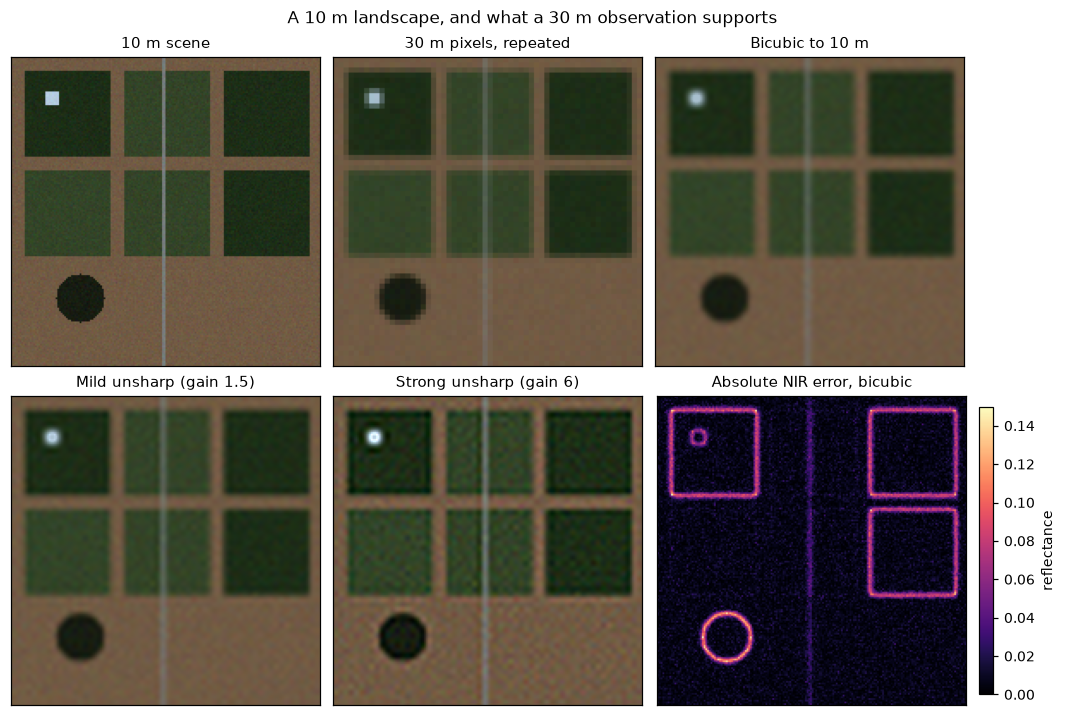

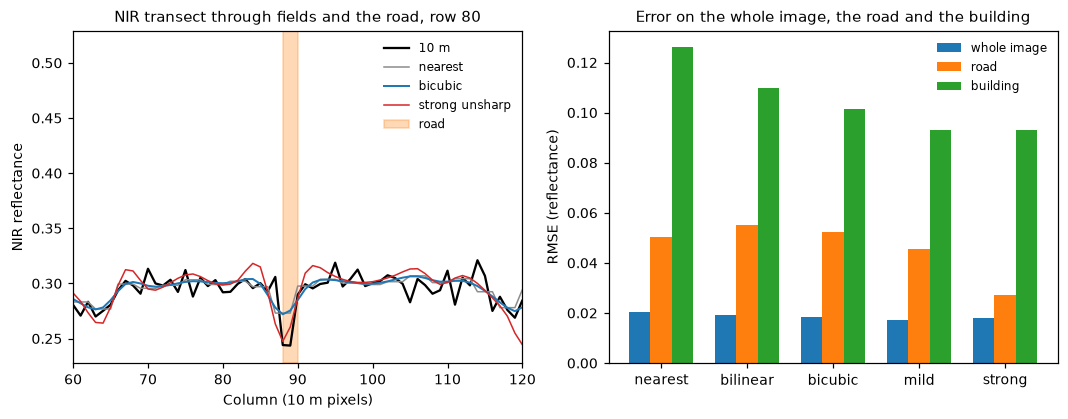

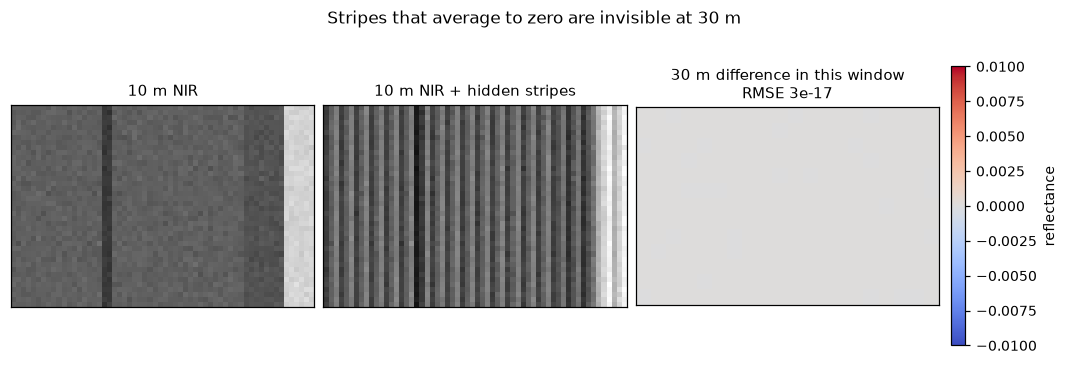

In [2]:
def as_rgb(img):  # red, green, blue image for display
    rgb = np.moveaxis(img[[2, 1, 0]], 0, -1)  # bands 2, 1, 0 -> (rows, cols, 3)
    return np.clip(rgb / 0.45, 0, 1)  # brighten (0.45 reflectance -> white) and clip


panels = [  # images and titles of the first five panels
    (as_rgb(hr), "10 m scene"),
    (as_rgb(methods["nearest"]), "30 m pixels, repeated"),
    (as_rgb(methods["bicubic"]), "Bicubic to 10 m"),
    (as_rgb(methods["unsharp, mild"]), "Mild unsharp (gain 1.5)"),
    (as_rgb(methods["unsharp, strong"]), "Strong unsharp (gain 6)"),
]
fig, axes = plt.subplots(2, 3, figsize=(9.6, 6.4), constrained_layout=True)  # 2 x 3 panels
for ax, (image, title) in zip(axes.ravel(), panels):  # the five images
    ax.imshow(image)  # show it
    ax.set_title(title)  # title
    ax.set_xticks([])  # no x ticks
    ax.set_yticks([])  # no y ticks
err_ax = axes[1, 2]  # the last panel
nir_error = np.abs(hr[3] - methods["bicubic"][3])  # absolute NIR error of bicubic interpolation
image = err_ax.imshow(nir_error, cmap="magma", vmin=0, vmax=0.15)  # show it
err_ax.set_title("Absolute NIR error, bicubic")  # title
err_ax.set_xticks([])  # no x ticks
err_ax.set_yticks([])  # no y ticks
fig.colorbar(image, ax=err_ax, fraction=0.046, pad=0.04, label="reflectance")  # colour bar
fig.suptitle("A 10 m landscape, and what a 30 m observation supports")  # overall title
plt.show()  # draw

row = 80  # the image row used for the transect
columns = np.arange(W)  # column numbers
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.7), constrained_layout=True)  # two panels
ax = axes[0]  # left panel
ax.plot(columns, hr[3, row], color="black", lw=1.5, label="10 m")  # the true NIR profile
ax.plot(columns, methods["nearest"][3, row], color="0.55", lw=1.0, label="nearest")  # nearest neighbour
ax.plot(columns, methods["bicubic"][3, row], color="C0", lw=1.3, label="bicubic")  # bicubic
# strong unsharp mask
ax.plot(columns, methods["unsharp, strong"][3, row], color="C3", lw=1.0, label="strong unsharp")
ax.axvspan(88, 90, color="C1", alpha=0.3, label="road")  # the road columns
ax.set_xlim(60, 120)  # zoom to columns 60-120
ax.set_xlabel("Column (10 m pixels)")  # x label
ax.set_ylabel("NIR reflectance")  # y label
ax.set_title(f"NIR transect through fields and the road, row {row}")  # title
ax.legend(fontsize=8, frameon=False)  # legend

ax = axes[1]  # right panel
order = ["nearest", "bilinear", "bicubic", "unsharp, mild", "unsharp, strong"]  # the methods in order
short = ["nearest", "bilinear", "bicubic", "mild", "strong"]  # short labels
xpos = np.arange(len(order))  # bar positions
width = 0.25  # bar width
series = [  # which error to plot, its label and colour
    ("RMSE", "whole image", "C0"),
    ("RMSE_road", "road", "C1"),
    ("RMSE_building", "building", "C2"),
]
for i, (key, label, color) in enumerate(series):  # each error type
    vals = [scores[name][key] for name in order]  # its values for every method
    ax.bar(xpos + (i - 1) * width, vals, width, label=label, color=color)  # bars shifted sideways
ax.set_xticks(xpos, short)  # method labels
ax.set_ylabel("RMSE (reflectance)")  # y label
ax.set_title("Error on the whole image, the road and the building")  # title
ax.legend(fontsize=8, frameon=False)  # legend
plt.show()  # draw

r0, r1, c0, c1 = 70, 110, 70, 130  # window around the road
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.4), constrained_layout=True)  # three panels
axes[0].imshow(hr[3, r0:r1, c0:c1], cmap="gray", vmin=0.15, vmax=0.55)  # true NIR in the window
axes[0].set_title("10 m NIR")  # title
axes[1].imshow(hr_alt[3, r0:r1, c0:c1], cmap="gray", vmin=0.15, vmax=0.55)  # NIR with the hidden stripes
axes[1].set_title("10 m NIR + hidden stripes")  # title
difference = lr_alt[3] - lr_clean[3]  # difference of the two 30 m observations
# Same window on the 30 m grid. Each coarse pixel covers one period of the stripes.
window = difference[r0 // SCALE:r1 // SCALE, c0 // SCALE:c1 // SCALE]
window_rmse = float(np.sqrt(np.mean(window ** 2)))  # its RMSE in the window
# show the difference
shown = axes[2].imshow(window, cmap="coolwarm", vmin=-0.01, vmax=0.01, interpolation="nearest")
axes[2].set_title(f"30 m difference in this window\nRMSE {window_rmse:.0e}")  # title
for ax in axes:  # for every panel
    ax.set_xticks([])  # no x ticks
    ax.set_yticks([])  # no y ticks
fig.colorbar(shown, ax=axes[2], fraction=0.046, pad=0.04, label="reflectance")  # colour bar
fig.suptitle("Stripes that average to zero are invisible at 30 m")  # overall title
plt.show()  # draw

### What the numbers say

The table is the whole argument of the notebook, on one scene.

**A better interpolator is a small gain.** Nearest neighbour, bilinear and bicubic land at RMSE 0.0205, 0.0192 and 0.0183. Bicubic reaches PSNR 34.77 dB, SSIM 0.881, SAM 3.26° and ERGAS 4.45. That is the best of the three resamplers, and ERGAS is still above the "about 3" rule of thumb used in pan-sharpening comparisons. Most of the reflectance was never lost: it sits in the coarse pixel. Interpolation only changes how the grid is drawn.

**The road is where that story breaks.** The road is 20 m wide, darker than the crop shoulders by 0.060 in NIR. Bicubic keeps 0.022 of that contrast, 36%. Nearest keeps 38% and bilinear 32%. Road RMSE stays near 0.05, while field RMSE is near 0.019. Bilinear is the better whole-image interpolator and the worst of the three on the road, because extra smoothing is exactly what a thin dark line cannot afford. The error map lights up along the road, the building outline and the field edges, and stays dark inside fields.

**The building is large enough to see and too small to be faithful.** Eight 10 m pixels is 80 m, between two and three coarse pixels. Building RMSE is 0.126 for nearest neighbour and 0.101 for bicubic. The bright core survives. The edges, which are most of an object this size, are mixtures.

**Mild sharpening undoes a little of a known blur. Strong sharpening trades one error for another.** Gain 1.5 moves whole-image RMSE from 0.0183 to 0.0174 and road contrast from 36% to 45%, and it improves SSIM, SAM, ERGAS and NDVI together. The forward model really is a blur, so a small inverse blur helps. Gain 6 keeps 73% of the road contrast and cuts road RMSE to 0.027, and the transect shows the dip returning, with lobes on either side. The whole image does not agree: SSIM falls to 0.864, SAM rises to 3.75° (the worst of the five) and NDVI RMSE rises to 0.098. A crisper road and a worse vegetation index are the same product.

**A comforting SAM does not mean the road is there.** Mean spectral angle stays near 3°. Most pixels are field interiors, and interpolation preserves their spectra. SAM is necessary for a material-sensitive product. It is a poor detector of a missing 20 m object.

**Field NDVI is slightly biased by mixing.** Mean NDVI on field pixels is 0.674 at 10 m and 0.643 after bicubic resampling. Edges mixed with soil and with the road pull the index down. A time series that switches from native 10 m Sentinel-2 to super-resolved Landsat will show a step from this effect alone if the edge fraction differs.

**The null-space pair is the definition of ill-posed.** Stripes of +0.05, −0.05 and 0 reflectance, one stripe per 10 m column, change the fine image by RMSE 0.0405. Each 30 m pixel covers exactly one period of that pattern, and the period sums to zero. Blur preserves the sum, so inside the fields the coarse images match: the third figure's window differs by numerical zero, on a colour scale of ±0.01 reflectance. Over the whole scene the coarse RMSE is 0.0015, 26.6 times smaller than the fine-image change, and that remainder is not recovered detail. It comes from the border of the blur and from pixels that clip at zero, especially the dark pond, where the negative stripe cannot be stored. A method that only matches the 30 m image is allowed to return either fine scene.

**Consistency is a weak test, and it is still worth running.** Degrading the true 10 m scene returns the clean 30 m image exactly (RMSE 0). Degrading the five estimates misses it by 0.0034 to 0.0064, the same order as the noise that was added (standard deviation 0.003). Mild unsharp masking is the closest, because it partly inverts the blur. All five would pass a casual consistency check. Passing it does not put the road back: the interpolators keep about a third of its contrast, and the gain that deepens the dip is the one that worsens NDVI. Consistency catches a model that paints detail the sensor rules out. It does not choose among the models the sensor allows.

The gap between bicubic and the true image is the room in which pan-sharpening, fusion and learned priors operate. They can use that room only by bringing information this coarse image does not contain.


## GeoLattice Super Resolution

GeoLattice provides a consistent API for classical image enlargement and deep-learning super-resolution in `geolattice.rsense.super_resolution`. The classical functions work with NumPy arrays; when given a georeferenced xarray object, `upsample` preserves its band names, CRS and spatial coordinates on the finer grid. GeoLattice raster I/O can read the original raster and write the result as a Cloud-Optimized GeoTIFF.

Install the base package for classical methods. The PyTorch models require the optional deep-learning dependencies:

```bash
pip install geolattice
pip install "geolattice[rsense-dl]"  # optional neural-network dependencies
```

This section reuses the known synthetic `lr` and `hr` arrays from the *Hands-on: a 10 m scene observed at 30 m* section, so each output can be scored against its true fine image. In a real satellite scene, the true high-resolution target is usually unavailable; use independent reference data and task-specific validation instead.


### Code 12 - call GeoLattice classical SR methods

`upsample` creates nearest, bicubic and Lanczos baselines at the 3× output scale. `unsharp_mask` adds local high-frequency contrast to bicubic output, and `iterative_back_projection` iteratively adjusts an estimate so that a simple blur-and-downsample model reproduces the observed coarse image. The latter two methods impose assumptions; they do not recover unique, unobserved detail. We score each estimate against the known synthetic fine image with the `score` helper defined earlier.


In [3]:
from geolattice.rsense import super_resolution as sr  # GeoLattice super-resolution tools

# Interpolation baselines: each array has shape (band, 180, 180).
geolattice_estimates = {
    "nearest": sr.upsample(lr, SCALE, method="nearest"),
    "bicubic": sr.upsample(lr, SCALE, method="bicubic"),
    "lanczos": sr.upsample(lr, SCALE, method="lanczos"),
}

# Sharpen a bicubic result; clipping keeps reflectance in its expected range.
geolattice_estimates["unsharp"] = sr.unsharp_mask(
    geolattice_estimates["bicubic"], amount=1.5, sigma=1.0, clip=(0.0, 1.0)
)

# Enforce consistency with a simple Gaussian-blur and 3 x 3 block model.
geolattice_estimates["back-projection"] = sr.iterative_back_projection(
    lr, scale=SCALE, iterations=12, blur_sigma=1.0, step=0.5,
    clip=(0.0, 1.0),
)

for name, estimate in geolattice_estimates.items():  # every GeoLattice estimate
    metrics = score(hr, estimate, masks)  # score it
    print(f"{name:>16}: RMSE={metrics['RMSE']:.4f}, "  # RMSE and spectral angle
          f"SAM={metrics['SAM']:.2f} degrees")

         nearest: RMSE=0.0211, SAM=3.42 degrees
         bicubic: RMSE=0.0196, SAM=3.37 degrees
         lanczos: RMSE=0.0182, SAM=3.25 degrees
         unsharp: RMSE=0.0190, SAM=3.32 degrees
 back-projection: RMSE=0.0174, SAM=3.33 degrees


### Deep-learning API

GeoLattice includes SRCNN-, VDSR-, EDSR- and RCAN-style multispectral models. Training is separate from model construction: prepare co-registered `(low_resolution, high_resolution)` pairs and a PyTorch `DataLoader`. A good training set should represent the sensor's point-spread function, reflectance scaling, cloud masks, and alignment-not just bicubic-degraded photographs.

The following is a usage pattern for a prepared `train_loader`; its batches must contain low-resolution tensors shaped `(batch, bands, rows, columns)` and matching fine targets at the requested scale. Use spatially separate scenes or blocks for validation. Tiled inference blends overlaps to reduce seams. For xarray input, the prediction keeps geospatial metadata.


Example usage (requires an existing `train_loader` of aligned low/high-resolution patches):

```python
# Optional: run after installing geolattice[rsense-dl] and preparing train_loader.
# Each batch from train_loader contains (low_resolution, high_resolution) tensors.
model = sr.build_sr_model(
    in_channels=4, scale=3, architecture="edsr", features=32, blocks=4
)
history = sr.train_super_resolution(
    model, train_loader, epochs=20, lr=1e-4,
    sam_weight=0.1, consistency_weight=0.1,
)

# `low_res_xarray` may be a georeferenced DataArray read with geolattice.rsense.read.
# The output retains CRS and spatial coordinates on the finer grid.
# fine_prediction = sr.predict_super_resolution(
#     model, low_res_xarray, tile=128, overlap=16, device="cuda"
# )
# rs.write(fine_prediction, "super_resolved.tif")
```


### Georeferenced raster workflow

For real imagery, read with `geolattice.rsense.read`, giving the band descriptions so model channel order is explicit. Upsampling a georeferenced `DataArray` keeps its CRS and affine grid while changing the pixel spacing. The same GeoLattice writer exports the result. The example uses placeholders: choose bands with a consistent reflectance scale, handle nodata/cloud masks, and do not treat resampling as recovered information.


In [4]:
# Replace these paths and band names with the products for your study area.
from geolattice import rsense as rs

# image = rs.read("landsat_surface_reflectance.tif",
#                 band_names=["blue", "green", "red", "nir"], masked=True)
# estimate = sr.upsample(image, scale=3, method="bicubic")
# rs.write(estimate, "landsat_bicubic_10m.tif", cog=True)

Interpolation and sharpening are useful baselines; a trained network is appropriate only when its training data and degradation match the target sensor. The companion Landsat/Sentinel-2 notebook demonstrates those methods on real, near-coincident scenes and discusses its masks, validation, and sensor-resolution limits.


## Summary, exercises and references

**Key ideas**

- Super-resolution estimates a fine image consistent with a coarse observation. The observation is a point-spread function, a sampler and noise, and that operator has a null space.
- Interpolation resamples $\mathbf{y}$. Pan-sharpening, guided super-resolution, spatiotemporal fusion and multi-frame methods each add a different real observation. Single-image networks add a prior learned from other scenes.
- Classical methods write the prior by hand (smoothness, a pan edge, a residual from another date). Deep models learn it. The training degradation has to resemble the sensor, or the learned inverse does not transfer.
- In remote sensing the expensive failures are spectral bias, a wrong point-spread function, a sub-pixel shift, and change between a reference date and the target date.
- Adversarial and diffusion models make sharper images and can invent objects. Use them for a measurement only with a pixel constraint and a task metric.
- On the synthetic scene, bicubic beats nearest neighbour by a small whole-image margin (RMSE 0.0183 against 0.0205) and keeps 36% of the contrast of a 20 m road. A stripe pattern whose 10 m RMSE is 26.6 times its 30 m RMSE shows why matching the coarse image is not enough.

**Exercises**

1. Widen the road from 2 pixels to 6 and then to 12 (20 m, 60 m, 120 m). At which width does bicubic interpolation keep at least half of the 10 m NIR contrast?
2. Set `SIGMA` to 0.4 and to 2.2 and rebuild the table. Which way does bicubic RMSE move, and which term in $\mathbf{y} = \mathbf{D}\mathbf{B}\mathbf{x} + \mathbf{n}$ did you change?
3. The hidden stripes have amplitude 0.05. Try two or three amplitudes and find when the 30 m RMSE exceeds 0.01. That amplitude is the size of fine-scale error a consistency check of 0.01 reflectance will tolerate.
4. Strong unsharp masking lowers road RMSE and raises NDVI RMSE. Which of the five estimates would you hand to someone digitising the road, and which to someone computing a field NDVI? Say what you would deliver alongside the raster.
5. A flood happens between the fine reference date and the coarse target date. Using the table in the *Evaluation, and choosing a method* section, which method is the wrong default, and which check would catch the copied pre-flood city?
6. Every estimate in the *Hands-on: a 10 m scene observed at 30 m* section has consistency RMSE below 0.007. Write two sentences a colleague can keep: what that number guarantees, and what it does not.

**References**

- Park, S.C., Park, M.K. & Kang, M.G. (2003). Super-resolution image reconstruction: a technical overview. *IEEE Signal Processing Magazine* 20(3), 21-36.
- Tsai, R.Y. & Huang, T.S. (1984). Multiframe image restoration and registration. In *Advances in Computer Vision and Image Processing*, vol. 1, pp. 317-339. JAI Press.
- Irani, M. & Peleg, S. (1991). Improving resolution by image registration. *CVGIP: Graphical Models and Image Processing* 53(3), 231-239.
- Wald, L., Ranchin, T. & Mangolini, M. (1997). Fusion of satellite images of different spatial resolutions: assessing the quality of resulting images. *Photogrammetric Engineering & Remote Sensing* 63(6), 691-699.
- Alparone, L., Aiazzi, B., Baronti, S., Garzelli, A., Nencini, F. & Selva, M. (2008). Multispectral and panchromatic data fusion assessment without reference. *Photogrammetric Engineering & Remote Sensing* 74(2), 193-200.
- Gao, F., Masek, J., Schwaller, M. & Hall, F. (2006). On the blending of the Landsat and MODIS surface reflectance: predicting daily Landsat surface reflectance. *IEEE Transactions on Geoscience and Remote Sensing* 44(8), 2207-2218.
- Zhu, X., Chen, J., Gao, F., Chen, X. & Masek, J.G. (2010). An enhanced spatial and temporal adaptive reflectance fusion model for complex heterogeneous regions. *Remote Sensing of Environment* 114(11), 2610-2623.
- Vivone, G. et al. (2015). A critical comparison among pansharpening algorithms. *IEEE Transactions on Geoscience and Remote Sensing* 53(5), 2565-2586.
- Claverie, M. et al. (2018). The Harmonized Landsat and Sentinel-2 surface reflectance data set. *Remote Sensing of Environment* 219, 145-161.
- Yokoya, N., Grohnfeldt, C. & Chanussot, J. (2017). Hyperspectral and multispectral data fusion: a comparative review of the recent literature. *IEEE Geoscience and Remote Sensing Magazine* 5(2), 29-56.
- Dong, C., Loy, C.C., He, K. & Tang, X. (2016). Image super-resolution using deep convolutional networks. *IEEE Transactions on Pattern Analysis and Machine Intelligence* 38(2), 295-307.
- Kim, J., Lee, J.K. & Lee, K.M. (2016). Accurate image super-resolution using very deep convolutional networks. In *CVPR*.
- Lim, B., Son, S., Kim, H., Nah, S. & Lee, K.M. (2017). Enhanced deep residual networks for single image super-resolution. In *CVPR Workshops*.
- Ledig, C. et al. (2017). Photo-realistic single image super-resolution using a generative adversarial network. In *CVPR*.
- Zhang, Y., Li, K., Li, K., Wang, L., Zhong, B. & Fu, Y. (2018). Image super-resolution using very deep residual channel attention networks. In *ECCV*.
- Wang, X. et al. (2018). ESRGAN: enhanced super-resolution generative adversarial networks. In *ECCV Workshops*.
- Lanaras, C., Bioucas-Dias, J., Galliani, S., Baltsavias, E. & Schindler, K. (2018). Super-resolution of Sentinel-2 images: learning a globally applicable deep neural network. *ISPRS Journal of Photogrammetry and Remote Sensing* 146, 305-319.
- Liang, J., Cao, J., Sun, G., Zhang, K., Van Gool, L. & Timofte, R. (2021). SwinIR: image restoration using Swin Transformer. In *ICCV Workshops*.
- Chen, Y., Liu, S. & Wang, X. (2021). Learning continuous image representation with local implicit image function. In *CVPR*.
- Wang, X., Xie, L., Dong, C. & Shan, Y. (2021). Real-ESRGAN: training real-world blind super-resolution with pure synthetic data. In *ICCV Workshops*.
- Shocher, A., Cohen, N. & Irani, M. (2018). Zero-shot super-resolution using deep internal learning. In *CVPR*.
- Chen, X., Wang, X., Zhou, J., Qiao, Y. & Dong, C. (2023). Activating more pixels in image super-resolution transformer. In *CVPR*.
- Saharia, C. et al. (2023). Image super-resolution via iterative refinement. *IEEE Transactions on Pattern Analysis and Machine Intelligence* 45(4), 4713-4726.
- Wang, P., Bayram, B. & Sertel, E. (2022). A comprehensive review on deep learning based remote sensing image super-resolution methods. *Earth-Science Reviews* 232, 104110.
- Liu, Y., Yue, J., Xia, S., Ghamisi, P., Xie, W. & Fang, L. (2024). Diffusion models meet remote sensing: principles, methods, and perspectives. *IEEE Transactions on Geoscience and Remote Sensing*. https://doi.org/10.1109/TGRS.2024.3464685
- Qi, Y., Lou, M., Liu, Y., Li, L., Yang, Z. & Nie, W. (2025). Advancing image super-resolution techniques in remote sensing: a comprehensive survey. *ISPRS Journal of Photogrammetry and Remote Sensing*. https://doi.org/10.1016/j.isprsjprs.2025.10.024

**Next:** [Landsat 8 to Sentinel-2: six-band super-resolution](09_08_01_landsat_8_to_sentinel_2_six_band_super_resolution.ipynb) runs this catalogue on imagery: co-registration and harmonisation, interpolation, high-pass detail injection, a STARFM-style fusion, a residual channel-attention network and a reference-guided network, scored with the measures in the *Evaluation, and choosing a method* section.
